# Apollo Hospitals — Complete EDA Project

### Appointment No-Show & Patient Engagement Analysis

**Required files:**
- `apollo_appointments_fact.csv`
- `apollo_doctors_dim.csv`

This notebook covers the complete EDA workflow: data understanding, no-show analysis, booking behaviour, reminders, patient engagement, revenue, insurance, doctor utilisation, waiting time, satisfaction, doctor experience vs consultation fee, final insights and business recommendations.

> **Business rules:** Quality metrics and revenue are analysed for Completed appointments. No-show rate uses Completed + No-Show + Cancelled as the denominator and excludes Scheduled appointments.

In [1]:
# ============================================================
# APOLLO HOSPITALS - COMPLETE EDA PROJECT
# Appointment No-Show & Patient Engagement Analysis
# ============================================================
#
# Files required in the same folder:
#   1. apollo_appointments_fact.csv
#   2. apollo_doctors_dim.csv
#
# This notebook/script answers the major project questions:
# 1. Data understanding & appointment status
# 2. No-show rate by specialty and city
# 3. Booking lead time
# 4. Evening / weekend / lead-time patterns
# 5. Appointment type & booking channel risk
# 6. Reminder effectiveness
# 7. Prior no-show history
# 8. Membership & repeat patients
# 9. Age / gender / chronic condition
# 10. Visit reasons
# 11. Age distributions
# 12. No-show revenue at risk
# 13. Average revenue by specialty & appointment type
# 14. City revenue & payment mix
# 15. Insurance vs out-of-pocket
# 16. Doctor utilisation
# 17. Waiting time
# 18. Consultation duration vs satisfaction
# 19. Doctor experience vs consultation fee
# 20. Final insights
# 21. Recommendations
#
# IMPORTANT BUSINESS RULES:
# - Quality metrics are valid only for Completed appointments.
# - Revenue analysis is restricted to Completed appointments.
# - No-show denominator = Completed + No-Show + Cancelled.
# - Scheduled appointments are excluded from no-show-rate calculations.
# - None in chronic condition/membership/insurance/cancellation reason
#   means the field does not apply; it is not automatically a missing value.
# - booking_lead_days = days between booking and appointment.
# - booking_lead_days = 0 means walk-in.
# ============================================================

import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")


In [2]:
# ------------------------------------------------------------
# 0. SETTINGS


In [3]:
# ------------------------------------------------------------

OUTPUT_DIR = "apollo_eda_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)


In [4]:
# ------------------------------------------------------------
# 1. LOAD DATA


In [5]:
# ------------------------------------------------------------

appointments = pd.read_csv("apollo_appointments_fact.csv")
doctors = pd.read_csv("apollo_doctors_dim.csv")

print("=" * 70)
print("APOLLO HOSPITALS - COMPLETE EDA")
print("=" * 70)

print("\nAppointments shape:", appointments.shape)
print("Doctors shape:", doctors.shape)

print("\nAppointment columns:")
print(appointments.columns.tolist())

print("\nDoctor columns:")
print(doctors.columns.tolist())


APOLLO HOSPITALS - COMPLETE EDA

Appointments shape: (75000, 52)
Doctors shape: (320, 15)

Appointment columns:
['appointment_id', 'patient_id', 'doctor_id', 'appointment_date', 'appointment_day', 'appointment_day_of_week', 'appointment_month', 'appointment_quarter', 'appointment_year', 'appointment_hour', 'appointment_minute', 'time_slot', 'time_of_day', 'booking_date', 'booking_lead_days', 'booking_channel', 'appointment_type', 'specialty', 'city', 'state', 'hospital_name', 'patient_age', 'age_group', 'patient_gender', 'patient_city_tier', 'patient_chronic_condition', 'apollo_member', 'membership_type', 'reminder_type', 'reminders_sent', 'patient_prior_visits', 'patient_prior_no_shows', 'is_first_visit', 'repeat_visit', 'visit_reason', 'appointment_status', 'no_show', 'no_show_flag', 'cancellation_reason', 'consultation_fee', 'discount_pct', 'actual_fee_charged', 'insurance_coverage', 'insurance_provider', 'insurance_covered_amount', 'patient_out_of_pocket', 'revenue_realized', 'paym

In [6]:
# ------------------------------------------------------------
# 2. BASIC DATA UNDERSTANDING


In [7]:
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("QUESTION 1 - DATA UNDERSTANDING")
print("=" * 70)

print("\nFirst 5 appointment rows:")
print(appointments.head())

print("\nAppointment status counts:")
status_counts = appointments["appointment_status"].value_counts()
print(status_counts)

print("\nAppointment status percentage:")
status_pct = (
    appointments["appointment_status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)
print(status_pct)

print("\nDuplicate appointment rows:", appointments.duplicated().sum())
print("Duplicate doctor rows:", doctors.duplicated().sum())

print("\nMissing values - top 20 columns:")
print(appointments.isnull().sum().sort_values(ascending=False).head(20))



QUESTION 1 - DATA UNDERSTANDING

First 5 appointment rows:
  appointment_id patient_id doctor_id appointment_date appointment_day  \
0    APPT5000001  PAT117608   DOC1035       2023-11-15       Wednesday   
1    APPT5000002  PAT128732   DOC1049       2023-03-13          Monday   
2    APPT5000003  PAT137532   DOC1033       2022-02-07          Monday   
3    APPT5000004  PAT113284   DOC1288       2023-11-20          Monday   
4    APPT5000005  PAT107443   DOC1064       2024-02-02          Friday   

   appointment_day_of_week  appointment_month appointment_quarter  \
0                        2                 11                  Q4   
1                        0                  3                  Q1   
2                        0                  2                  Q1   
3                        0                 11                  Q4   
4                        4                  2                  Q1   

   appointment_year  appointment_hour  ...  insurance_coverage  \
0             

In [8]:
# ------------------------------------------------------------
# 3. COMMON DATASETS


In [9]:
# ------------------------------------------------------------

valid_appointments = appointments[
    appointments["appointment_status"].isin(
        ["Completed", "No-Show", "Cancelled"]
    )
].copy()

completed = appointments[
    appointments["appointment_status"] == "Completed"
].copy()

no_shows = appointments[
    appointments["appointment_status"] == "No-Show"
].copy()

cancelled = appointments[
    appointments["appointment_status"] == "Cancelled"
].copy()

scheduled = appointments[
    appointments["appointment_status"] == "Scheduled"
].copy()


In [10]:
# ------------------------------------------------------------
# HELPER FUNCTION


In [11]:
# ------------------------------------------------------------

def no_show_rate_table(df, group_col):
    """
    No-show rate denominator:
    Completed + No-Show + Cancelled
    Scheduled is excluded.
    """
    temp = df[
        df["appointment_status"].isin(
            ["Completed", "No-Show", "Cancelled"]
        )
    ].copy()

    result = (
        temp.groupby(group_col)
        .agg(
            total_valid_appointments=("appointment_status", "size"),
            no_shows=("appointment_status", lambda x: (x == "No-Show").sum()),
            completed=("appointment_status", lambda x: (x == "Completed").sum()),
            cancelled=("appointment_status", lambda x: (x == "Cancelled").sum()),
        )
        .reset_index()
    )

    result["no_show_rate_pct"] = (
        result["no_shows"] / result["total_valid_appointments"] * 100
    )

    return result.sort_values("no_show_rate_pct", ascending=False)


In [12]:
# ------------------------------------------------------------
# 4. NO-SHOW RATE BY SPECIALTY



QUESTION 2A - NO-SHOW RATE BY SPECIALTY
        specialty  total_valid_appointments  no_shows  completed  cancelled  no_show_rate_pct
       Psychiatry                      2900       711       1958        231         24.517241
      Dermatology                      7566      1608       5347        611         21.252974
              ENT                      5211       988       3845        378         18.959893
    Endocrinology                      2024       355       1504        165         17.539526
    Ophthalmology                      3103       503       2349        251         16.210119
General Physician                     19654      3049      14981       1624         15.513381
      Pulmonology                      2549       394       1961        194         15.457042
     Orthopaedics                      5419       810       4189        420         14.947407
 Gastroenterology                      2527       377       1972        178         14.918876
          Urology  

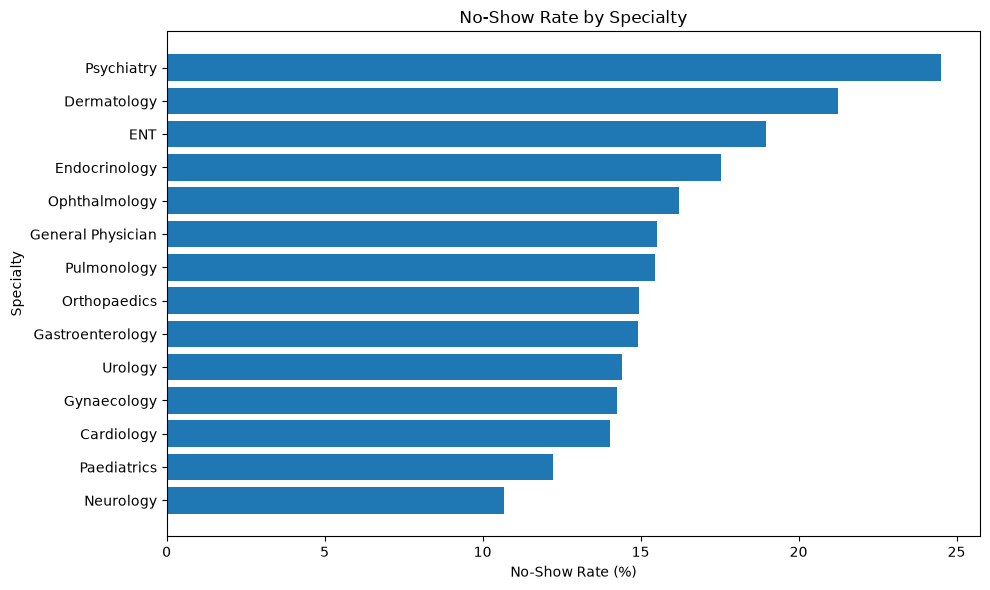

In [13]:
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("QUESTION 2A - NO-SHOW RATE BY SPECIALTY")
print("=" * 70)

specialty_no_show = no_show_rate_table(
    appointments, "specialty"
)

print(specialty_no_show.to_string(index=False))

plt.figure(figsize=(10, 6))
plt.barh(
    specialty_no_show["specialty"],
    specialty_no_show["no_show_rate_pct"]
)
plt.xlabel("No-Show Rate (%)")
plt.ylabel("Specialty")
plt.title("No-Show Rate by Specialty")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "01_no_show_rate_specialty.png"),
    dpi=150
)
plt.show()


In [14]:
# ------------------------------------------------------------
# 5. NO-SHOW RATE BY CITY



QUESTION 2B - NO-SHOW RATE BY CITY
      city  total_valid_appointments  no_shows  completed  cancelled  no_show_rate_pct
   Lucknow                      3001       516       2254        231         17.194269
    Mumbai                      9734      1659       7318        757         17.043353
     Delhi                     10404      1754       7834        816         16.858900
    Bhopal                      2001       336       1518        147         16.791604
   Kolkata                      5701       933       4280        488         16.365550
     Kochi                      2690       438       2030        222         16.282528
 Ahmedabad                      3468       561       2607        300         16.176471
    Jaipur                      2653       429       2005        219         16.170373
 Hyderabad                      7229      1160       5496        573         16.046479
 Bengaluru                      8343      1287       6405        651         15.426106
Chandig

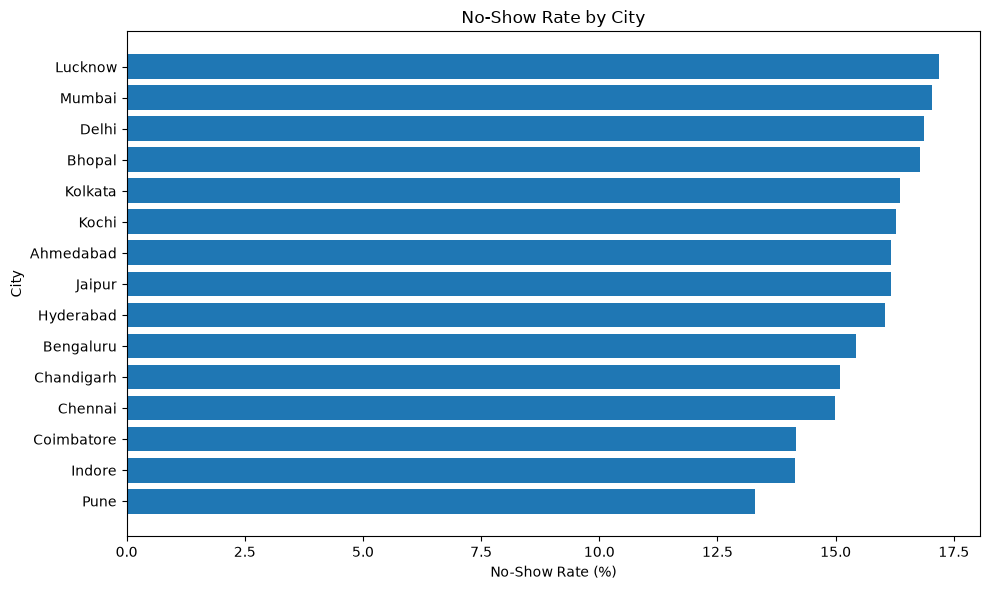

In [15]:
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("QUESTION 2B - NO-SHOW RATE BY CITY")
print("=" * 70)

city_no_show = no_show_rate_table(
    appointments, "city"
)

print(city_no_show.to_string(index=False))

plt.figure(figsize=(10, 6))
plt.barh(
    city_no_show["city"],
    city_no_show["no_show_rate_pct"]
)
plt.xlabel("No-Show Rate (%)")
plt.ylabel("City")
plt.title("No-Show Rate by City")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "02_no_show_rate_city.png"),
    dpi=150
)
plt.show()


In [16]:
# ------------------------------------------------------------
# 6. BOOKING LEAD TIME



QUESTION 3 - BOOKING LEAD TIME

Booking lead days summary:
count    75000.000000
mean         3.622373
std          4.387804
min          0.000000
25%          0.000000
50%          2.000000
75%          5.000000
max         30.000000
Name: booking_lead_days, dtype: float64

Lead-time no-show analysis:
    booking_lead_days  total  no_shows  no_show_rate_pct
0                   0  20180      3193         15.822597
1                   1  10453      1382         13.221085
2                   2   8227      1202         14.610429
3                   3   6795      1067         15.702723
4                   4   5395       900         16.682113
5                   5   4384       706         16.104015
6                   6   3310       490         14.803625
7                   7   2808       527         18.767806
8                   8   2227       416         18.679838
9                   9   1777       332         18.683174
10                 10   1400       247         17.642857
11         

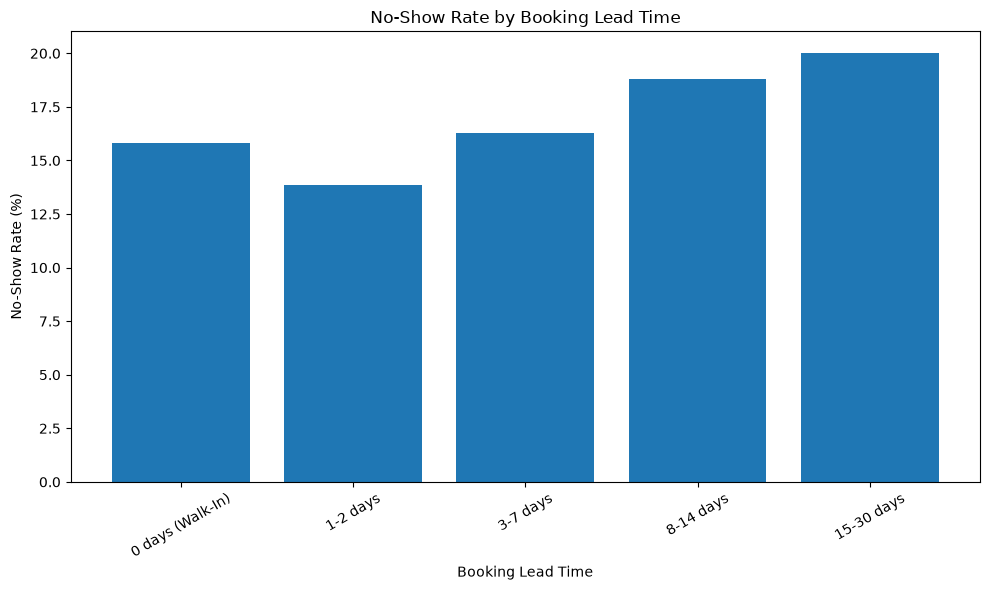

In [17]:
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("QUESTION 3 - BOOKING LEAD TIME")
print("=" * 70)

print("\nBooking lead days summary:")
print(appointments["booking_lead_days"].describe())

lead_time_summary = (
    valid_appointments
    .groupby("booking_lead_days")["appointment_status"]
    .agg(
        total="size",
        no_shows=lambda x: (x == "No-Show").sum()
    )
    .reset_index()
)

lead_time_summary["no_show_rate_pct"] = (
    lead_time_summary["no_shows"]
    / lead_time_summary["total"]
    * 100
)

print("\nLead-time no-show analysis:")
print(lead_time_summary.head(20))

# Lead-time buckets
def lead_bucket(x):
    if x == 0:
        return "0 days (Walk-In)"
    elif x <= 2:
        return "1-2 days"
    elif x <= 7:
        return "3-7 days"
    elif x <= 14:
        return "8-14 days"
    elif x <= 30:
        return "15-30 days"
    else:
        return "31+ days"

valid_appointments["lead_time_bucket"] = (
    valid_appointments["booking_lead_days"]
    .apply(lead_bucket)
)

lead_bucket_order = [
    "0 days (Walk-In)",
    "1-2 days",
    "3-7 days",
    "8-14 days",
    "15-30 days",
    "31+ days"
]

lead_bucket_analysis = (
    valid_appointments
    .groupby("lead_time_bucket")["appointment_status"]
    .agg(
        total="size",
        no_shows=lambda x: (x == "No-Show").sum()
    )
    .reindex(lead_bucket_order)
    .reset_index()
)

lead_bucket_analysis["no_show_rate_pct"] = (
    lead_bucket_analysis["no_shows"]
    / lead_bucket_analysis["total"]
    * 100
)

print("\nLead-time bucket analysis:")
print(lead_bucket_analysis.to_string(index=False))

plt.figure(figsize=(10, 6))
plt.bar(
    lead_bucket_analysis["lead_time_bucket"],
    lead_bucket_analysis["no_show_rate_pct"]
)
plt.xlabel("Booking Lead Time")
plt.ylabel("No-Show Rate (%)")
plt.title("No-Show Rate by Booking Lead Time")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "03_no_show_lead_time.png"),
    dpi=150
)
plt.show()


In [18]:
# ------------------------------------------------------------
# 7. EVENING / WEEKEND / LEAD TIME


In [19]:
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("QUESTION 4 - EVENING, WEEKEND & LEAD TIME")
print("=" * 70)

if "time_of_day" in valid_appointments.columns:
    time_no_show = no_show_rate_table(
        appointments, "time_of_day"
    )
    print("\nNo-show rate by time of day:")
    print(time_no_show.to_string(index=False))

if "appointment_day" in valid_appointments.columns:
    day_no_show = no_show_rate_table(
        appointments, "appointment_day"
    )
    print("\nNo-show rate by appointment day:")
    print(day_no_show.to_string(index=False))

if "appointment_day" in valid_appointments.columns:
    weekend_days = ["Saturday", "Sunday"]
    valid_appointments["is_weekend"] = (
        valid_appointments["appointment_day"].isin(weekend_days)
    )

    weekend_analysis = (
        valid_appointments
        .groupby("is_weekend")["appointment_status"]
        .agg(
            total="size",
            no_shows=lambda x: (x == "No-Show").sum()
        )
        .reset_index()
    )

    weekend_analysis["no_show_rate_pct"] = (
        weekend_analysis["no_shows"]
        / weekend_analysis["total"]
        * 100
    )

    print("\nWeekend vs weekday:")
    print(weekend_analysis)



QUESTION 4 - EVENING, WEEKEND & LEAD TIME

No-show rate by time of day:
time_of_day  total_valid_appointments  no_shows  completed  cancelled  no_show_rate_pct
    Evening                     14553      2673      10718       1162         18.367347
  Afternoon                     23231      4124      17270       1837         17.752142
    Morning                     34868      4787      27287       2794         13.728921

No-show rate by appointment day:
appointment_day  total_valid_appointments  no_shows  completed  cancelled  no_show_rate_pct
         Sunday                     10531      1969       7745        817         18.697180
       Saturday                     10390      1939       7616        835         18.662175
      Wednesday                     10397      1620       7964        813         15.581418
       Thursday                     10470      1583       8028        859         15.119389
         Friday                     10301      1535       7984        782        

In [20]:
# ------------------------------------------------------------
# 8. APPOINTMENT TYPE & BOOKING CHANNEL


In [21]:
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("QUESTION 5 - APPOINTMENT TYPE & BOOKING CHANNEL")
print("=" * 70)

if "appointment_type" in appointments.columns:
    type_no_show = no_show_rate_table(
        appointments, "appointment_type"
    )
    print("\nNo-show rate by appointment type:")
    print(type_no_show.to_string(index=False))

if "booking_channel" in appointments.columns:
    channel_no_show = no_show_rate_table(
        appointments, "booking_channel"
    )
    print("\nNo-show rate by booking channel:")
    print(channel_no_show.to_string(index=False))



QUESTION 5 - APPOINTMENT TYPE & BOOKING CHANNEL

No-show rate by appointment type:
appointment_type  total_valid_appointments  no_shows  completed  cancelled  no_show_rate_pct
      Home Visit                      9742      2557       6436        749         26.247177
   Video Consult                     15349      3232      10901       1216         21.056746
       In-Clinic                     47561      5795      37938       3828         12.184353

No-show rate by booking channel:
booking_channel  total_valid_appointments  no_shows  completed  cancelled  no_show_rate_pct
        Walk-In                      7281      1520       5177        584         20.876253
    Partner App                      3594       651       2645        298         18.113523
        Website                     17964      3090      13369       1505         17.201069
    Call Centre                     10855      1650       8339        866         15.200368
     Apollo App                     32958      467

In [22]:
# ------------------------------------------------------------
# 9. REMINDER EFFECTIVENESS



QUESTION 6 - REMINDER EFFECTIVENESS

No-show rate by reminders sent:
 reminders_sent  total_valid_appointments  no_shows  completed  cancelled  no_show_rate_pct
              0                     10977      3311       6766        900         30.163068
              1                     14527      2363      10985       1179         16.266263
              2                     25273      3414      19933       1926         13.508487
              3                     21875      2496      17591       1788         11.410286


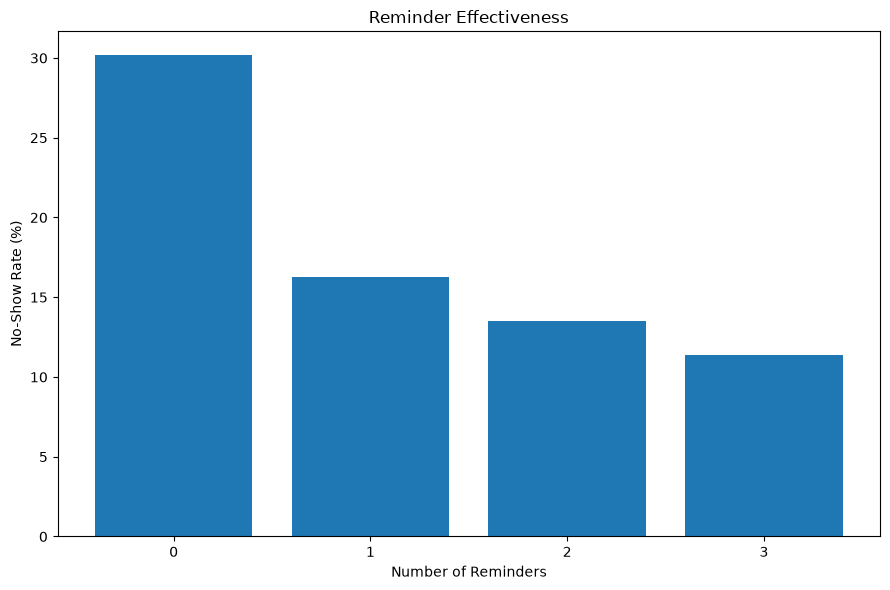

In [23]:
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("QUESTION 6 - REMINDER EFFECTIVENESS")
print("=" * 70)

if "reminders_sent" in appointments.columns:
    reminder_analysis = no_show_rate_table(
        appointments, "reminders_sent"
    )
    print("\nNo-show rate by reminders sent:")
    print(reminder_analysis.to_string(index=False))

    plt.figure(figsize=(9, 6))
    plt.bar(
        reminder_analysis["reminders_sent"].astype(str),
        reminder_analysis["no_show_rate_pct"]
    )
    plt.xlabel("Number of Reminders")
    plt.ylabel("No-Show Rate (%)")
    plt.title("Reminder Effectiveness")
    plt.tight_layout()
    plt.savefig(
        os.path.join(OUTPUT_DIR, "04_reminder_effectiveness.png"),
        dpi=150
    )
    plt.show()


In [24]:
# ------------------------------------------------------------
# 10. PRIOR NO-SHOW HISTORY


In [25]:
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("QUESTION 7 - PRIOR NO-SHOW HISTORY")
print("=" * 70)

if "patient_prior_no_shows" in appointments.columns:
    prior_no_show_analysis = no_show_rate_table(
        appointments, "patient_prior_no_shows"
    )

    print("\nNo-show rate by previous no-shows:")
    print(prior_no_show_analysis.to_string(index=False))



QUESTION 7 - PRIOR NO-SHOW HISTORY

No-show rate by previous no-shows:
 patient_prior_no_shows  total_valid_appointments  no_shows  completed  cancelled  no_show_rate_pct
                      4                        16         8          8          0         50.000000
                      5                         2         1          1          0         50.000000
                      3                       134        41         84          9         30.597015
                      2                       983       262        637         84         26.653103
                      1                      8502      1723       6106        673         20.265820
                      0                     63014      9549      48438       5027         15.153775
                      6                         1         0          1          0          0.000000


In [26]:
# ------------------------------------------------------------
# 11. MEMBERSHIP & REPEAT PATIENTS


In [27]:
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("QUESTION 8 - MEMBERSHIP & REPEAT PATIENTS")
print("=" * 70)

if "membership_type" in appointments.columns:
    membership_analysis = no_show_rate_table(
        appointments, "membership_type"
    )
    print("\nNo-show rate by membership type:")
    print(membership_analysis.to_string(index=False))

if "is_first_visit" in appointments.columns:
    first_visit_analysis = no_show_rate_table(
        appointments, "is_first_visit"
    )
    print("\nNo-show rate by first visit:")
    print(first_visit_analysis.to_string(index=False))



QUESTION 8 - MEMBERSHIP & REPEAT PATIENTS

No-show rate by membership type:
membership_type  total_valid_appointments  no_shows  completed  cancelled  no_show_rate_pct
  Apollo Silver                      8057      1021       6417        619         12.672211
    Apollo Gold                      8167      1033       6456        678         12.648463

No-show rate by first visit:
 is_first_visit  total_valid_appointments  no_shows  completed  cancelled  no_show_rate_pct
              1                      9182      6132          0       3050         66.782836
              0                     63470      5452      55275       2743          8.589885


In [28]:
# ------------------------------------------------------------
# 12. AGE / GENDER / CHRONIC CONDITION


In [29]:
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("QUESTION 9 - AGE, GENDER & CHRONIC CONDITION")
print("=" * 70)

if "age" in appointments.columns:
    age_bins = [0, 12, 18, 30, 45, 60, 100]
    age_labels = [
        "0-12", "13-18", "19-30",
        "31-45", "46-60", "61+"
    ]

    valid_appointments["age_group"] = pd.cut(
        valid_appointments["age"],
        bins=age_bins,
        labels=age_labels,
        include_lowest=True
    )

    age_no_show = no_show_rate_table(
        valid_appointments, "age_group"
    )

    print("\nNo-show rate by age group:")
    print(age_no_show.to_string(index=False))

if "gender" in appointments.columns:
    gender_no_show = no_show_rate_table(
        appointments, "gender"
    )
    print("\nNo-show rate by gender:")
    print(gender_no_show.to_string(index=False))

if "chronic_condition" in appointments.columns:
    chronic_no_show = no_show_rate_table(
        appointments, "chronic_condition"
    )
    print("\nNo-show rate by chronic condition:")
    print(chronic_no_show.to_string(index=False))



QUESTION 9 - AGE, GENDER & CHRONIC CONDITION


In [30]:
# ------------------------------------------------------------
# 13. VISIT REASONS


In [31]:
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("QUESTION 10 - VISIT REASONS")
print("=" * 70)

if "visit_reason" in appointments.columns:
    reason_no_show = no_show_rate_table(
        appointments, "visit_reason"
    )
    print("\nNo-show rate by visit reason:")
    print(reason_no_show.to_string(index=False))



QUESTION 10 - VISIT REASONS

No-show rate by visit reason:
                visit_reason  total_valid_appointments  no_shows  completed  cancelled  no_show_rate_pct
                  Skin Issue                      2782       467       2093        222         16.786485
                  Joint Pain                      6469      1082       4880        507         16.725924
             Cardiac Concern                      2639       430       2002        207         16.294051
               Mental Health                      2733       445       2046        242         16.282473
           Digestive Problem                      7984      1297       6060        627         16.244990
                      Injury                      5884       949       4482        453         16.128484
           Fever & Infection                      6808      1095       5196        517         16.084019
           Respiratory Issue                      6383      1020       4817        546         15.97

In [32]:
# ------------------------------------------------------------
# 14. AGE DISTRIBUTION FOR KEY SPECIALTIES


In [33]:
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("QUESTION 11 - AGE DISTRIBUTION BY SPECIALTY")
print("=" * 70)

if "specialty" in appointments.columns and "age" in appointments.columns:
    selected_specialties = [
        "Gynaecology",
        "Paediatrics",
        "Psychiatry"
    ]

    for specialty in selected_specialties:
        subset = appointments[
            appointments["specialty"] == specialty
        ]

        if len(subset) > 0:
            print(f"\n{specialty}:")
            print("Count:", len(subset))
            print("Mean age:", round(subset["age"].mean(), 2))
            print("Median age:", subset["age"].median())
            print("Minimum age:", subset["age"].min())
            print("Maximum age:", subset["age"].max())



QUESTION 11 - AGE DISTRIBUTION BY SPECIALTY


In [34]:
# ------------------------------------------------------------
# 15. NO-SHOW REVENUE AT RISK


In [35]:
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("QUESTION 12 - NO-SHOW REVENUE AT RISK")
print("=" * 70)

if "consultation_fee" in appointments.columns:
    no_show_revenue_at_risk = no_shows["consultation_fee"].sum()

    completed_revenue = (
        completed["revenue_realized"].sum()
        if "revenue_realized" in completed.columns
        else np.nan
    )

    print(
        f"\nPotential consultation-fee revenue at risk: "
        f"₹{no_show_revenue_at_risk:,.2f}"
    )

    if pd.notna(completed_revenue) and completed_revenue != 0:
        risk_pct = (
            no_show_revenue_at_risk
            / completed_revenue
            * 100
        )

        print(
            f"At-risk fee as % of completed realized revenue: "
            f"{risk_pct:.2f}%"
        )

    print(
        "\nNOTE: This is potential listed consultation-fee revenue "
        "associated with no-shows, not necessarily an accounting loss."
    )



QUESTION 12 - NO-SHOW REVENUE AT RISK

Potential consultation-fee revenue at risk: ₹19,725,460.00
At-risk fee as % of completed realized revenue: 26.69%

NOTE: This is potential listed consultation-fee revenue associated with no-shows, not necessarily an accounting loss.


In [36]:
# ------------------------------------------------------------
# 16. AVERAGE REVENUE BY SPECIALTY


In [37]:
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("QUESTION 13A - AVERAGE REALIZED REVENUE BY SPECIALTY")
print("=" * 70)

if "revenue_realized" in completed.columns:
    specialty_revenue = (
        completed
        .groupby("specialty")["revenue_realized"]
        .mean()
        .sort_values(ascending=False)
        .reset_index()
    )

    specialty_revenue["revenue_realized"] = (
        specialty_revenue["revenue_realized"].round(2)
    )

    print(specialty_revenue.to_string(index=False))



QUESTION 13A - AVERAGE REALIZED REVENUE BY SPECIALTY
        specialty  revenue_realized
       Psychiatry           2640.45
        Neurology           2076.48
          Urology           1988.62
       Cardiology           1940.77
 Gastroenterology           1896.82
    Endocrinology           1812.68
      Pulmonology           1803.23
     Orthopaedics           1547.20
      Gynaecology           1499.59
    Ophthalmology           1467.13
      Dermatology           1306.92
              ENT           1204.48
      Paediatrics            949.73
General Physician            632.79


In [38]:
# ------------------------------------------------------------
# 17. AVERAGE REVENUE BY APPOINTMENT TYPE


In [39]:
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("QUESTION 13B - AVERAGE REALIZED REVENUE BY APPOINTMENT TYPE")
print("=" * 70)

if (
    "revenue_realized" in completed.columns
    and "appointment_type" in completed.columns
):
    type_revenue = (
        completed
        .groupby("appointment_type")["revenue_realized"]
        .mean()
        .sort_values(ascending=False)
        .reset_index()
    )

    type_revenue["revenue_realized"] = (
        type_revenue["revenue_realized"].round(2)
    )

    print(type_revenue.to_string(index=False))



QUESTION 13B - AVERAGE REALIZED REVENUE BY APPOINTMENT TYPE
appointment_type  revenue_realized
      Home Visit           1960.05
       In-Clinic           1299.83
   Video Consult           1097.70


In [40]:
# ------------------------------------------------------------
# 18. CITY TOTAL REVENUE


In [41]:
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("QUESTION 14A - CITY TOTAL REALIZED REVENUE")
print("=" * 70)

if "revenue_realized" in completed.columns:
    city_revenue = (
        completed
        .groupby("city")["revenue_realized"]
        .sum()
        .sort_values(ascending=False)
        .reset_index()
    )

    city_revenue["revenue_realized"] = (
        city_revenue["revenue_realized"].round(2)
    )

    print(city_revenue.to_string(index=False))



QUESTION 14A - CITY TOTAL REALIZED REVENUE
      city  revenue_realized
 Bengaluru           9990616
     Delhi           9958247
    Mumbai           8989613
 Hyderabad           7503245
   Chennai           7188473
   Kolkata           6543084
      Pune           4734139
 Ahmedabad           3956890
   Lucknow           3177444
    Indore           2223207
Chandigarh           2221091
    Jaipur           2199116
Coimbatore           1792804
     Kochi           1731448
    Bhopal           1684381


In [42]:
# ------------------------------------------------------------
# 19. PAYMENT MODE MIX



QUESTION 14B - PAYMENT MODE MIX
payment_mode  appointments  percentage
   Insurance         11641       21.06
  Debit Card          7353       13.30
 Net Banking          7349       13.30
  Apollo Pay          7324       13.25
         UPI          7259       13.13
 Credit Card          7213       13.05
        Cash          7136       12.91


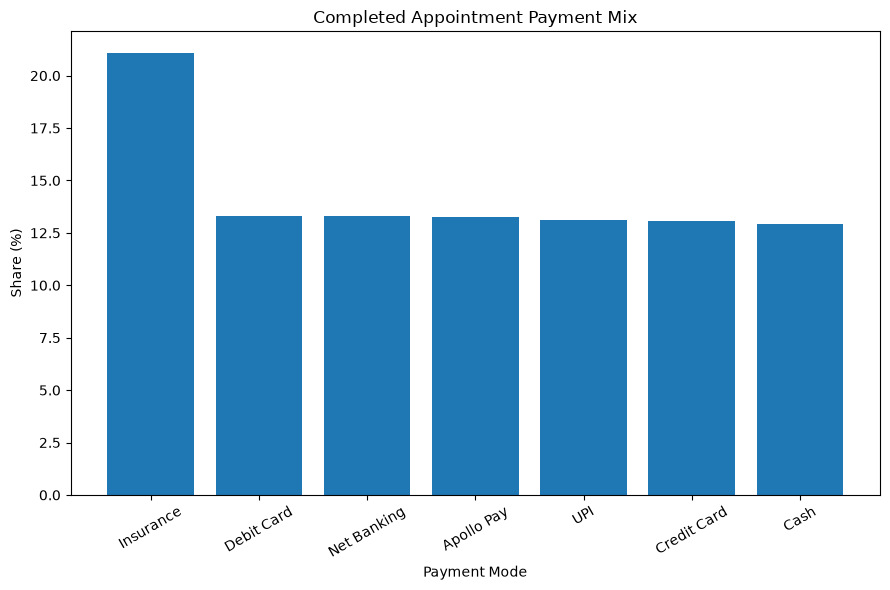

In [43]:
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("QUESTION 14B - PAYMENT MODE MIX")
print("=" * 70)

if "payment_mode" in completed.columns:
    payment_mix = (
        completed["payment_mode"]
        .value_counts()
        .rename_axis("payment_mode")
        .reset_index(name="appointments")
    )

    payment_mix["percentage"] = (
        payment_mix["appointments"]
        / payment_mix["appointments"].sum()
        * 100
    ).round(2)

    print(payment_mix.to_string(index=False))

    plt.figure(figsize=(9, 6))
    plt.bar(
        payment_mix["payment_mode"],
        payment_mix["percentage"]
    )
    plt.xlabel("Payment Mode")
    plt.ylabel("Share (%)")
    plt.title("Completed Appointment Payment Mix")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.savefig(
        os.path.join(OUTPUT_DIR, "05_payment_mix.png"),
        dpi=150
    )
    plt.show()


In [44]:
# ------------------------------------------------------------
# 20. INSURANCE VS OUT-OF-POCKET


In [45]:
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("QUESTION 15 - INSURANCE VS OUT-OF-POCKET")
print("=" * 70)

insurance_cols = [
    "insurance_coverage",
    "insurance_covered_amount",
    "patient_out_of_pocket"
]

available_insurance_cols = [
    c for c in insurance_cols if c in completed.columns
]

if available_insurance_cols:
    print("\nInsurance summary:")
    print(
        completed[available_insurance_cols]
        .describe()
    )

if "insurance_coverage" in completed.columns:
    insurance_summary = (
        completed
        .groupby("insurance_coverage")
        .agg(
            appointments=("appointment_status", "size"),
            avg_covered_amount=("insurance_covered_amount", "mean")
            if "insurance_covered_amount" in completed.columns
            else ("appointment_status", "size")
        )
        .reset_index()
    )

    print("\nInsurance coverage summary:")
    print(insurance_summary)

if (
    "insurance_covered_amount" in completed.columns
    and "patient_out_of_pocket" in completed.columns
):
    insurance_out_of_pocket = pd.DataFrame({
        "metric": [
            "Total insurance covered",
            "Total patient out-of-pocket",
            "Average insurance covered per completed appointment",
            "Average patient out-of-pocket per completed appointment"
        ],
        "value": [
            completed["insurance_covered_amount"].sum(),
            completed["patient_out_of_pocket"].sum(),
            completed["insurance_covered_amount"].mean(),
            completed["patient_out_of_pocket"].mean()
        ]
    })

    print("\nInsurance vs out-of-pocket:")
    print(insurance_out_of_pocket)



QUESTION 15 - INSURANCE VS OUT-OF-POCKET

Insurance summary:
       insurance_covered_amount  patient_out_of_pocket
count              55275.000000           55275.000000
mean                 223.902867            1336.839403
std                  533.692298             847.575941
min                    0.000000               1.000000
25%                    0.000000             680.000000
50%                    0.000000            1275.000000
75%                    0.000000            1900.000000
max                 5321.000000            5400.000000

Insurance coverage summary:
  insurance_coverage  appointments  avg_covered_amount
0                 No         37523            0.000000
1                Yes         17752          697.173896

Insurance vs out-of-pocket:
                                              metric         value
0                            Total insurance covered  1.237623e+07
1                        Total patient out-of-pocket  7.389380e+07
2  Average insuranc

In [46]:
# ------------------------------------------------------------
# 21. DOCTOR UTILISATION


In [47]:
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("QUESTION 16 - DOCTOR UTILISATION")
print("=" * 70)

if "doctor_utilization_pct" in completed.columns:
    doctor_utilization = (
        completed
        .groupby("doctor_id")["doctor_utilization_pct"]
        .mean()
        .sort_values(ascending=False)
        .reset_index()
    )

    print("\nTop 10 doctors by average utilisation:")
    print(
        doctor_utilization.head(10)
        .to_string(index=False)
    )

    print("\nOverall average doctor utilisation:")
    print(
        round(
            completed["doctor_utilization_pct"].mean(),
            2
        ),
        "%"
    )



QUESTION 16 - DOCTOR UTILISATION

Top 10 doctors by average utilisation:
doctor_id  doctor_utilization_pct
  DOC1128               79.886861
  DOC1201               79.448428
  DOC1157               78.652258
  DOC1141               78.636111
  DOC1197               78.615347
  DOC1255               78.585165
  DOC1007               78.498925
  DOC1275               78.494776
  DOC1091               78.462179
  DOC1319               78.404348

Overall average doctor utilisation:
76.57 %


In [48]:
# ------------------------------------------------------------
# 22. WAITING TIME


In [49]:
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("QUESTION 17 - WAITING TIME")
print("=" * 70)

if "wait_time_minutes" in completed.columns:
    waiting_summary = completed["wait_time_minutes"].describe()

    print("\nWaiting time summary:")
    print(waiting_summary)

    if "specialty" in completed.columns:
        wait_by_specialty = (
            completed
            .groupby("specialty")["wait_time_minutes"]
            .mean()
            .sort_values(ascending=False)
            .reset_index()
        )

        wait_by_specialty["wait_time_minutes"] = (
            wait_by_specialty["wait_time_minutes"].round(2)
        )

        print("\nAverage waiting time by specialty:")
        print(wait_by_specialty.to_string(index=False))



QUESTION 17 - WAITING TIME

Waiting time summary:
count    55275.000000
mean        11.549597
std         12.052208
min          0.000000
25%          3.000000
50%          8.000000
75%         16.000000
max         90.000000
Name: wait_time_minutes, dtype: float64

Average waiting time by specialty:
        specialty  wait_time_minutes
    Ophthalmology              12.02
          Urology              11.91
      Dermatology              11.77
     Orthopaedics              11.70
        Neurology              11.64
      Gynaecology              11.62
       Cardiology              11.59
General Physician              11.53
    Endocrinology              11.46
 Gastroenterology              11.39
      Pulmonology              11.39
       Psychiatry              11.34
              ENT              11.30
      Paediatrics              11.18


In [50]:
# ------------------------------------------------------------
# 23. CONSULTATION DURATION VS SATISFACTION



QUESTION 18 - CONSULTATION DURATION VS SATISFACTION

Correlation between consultation duration and satisfaction:
-0.004


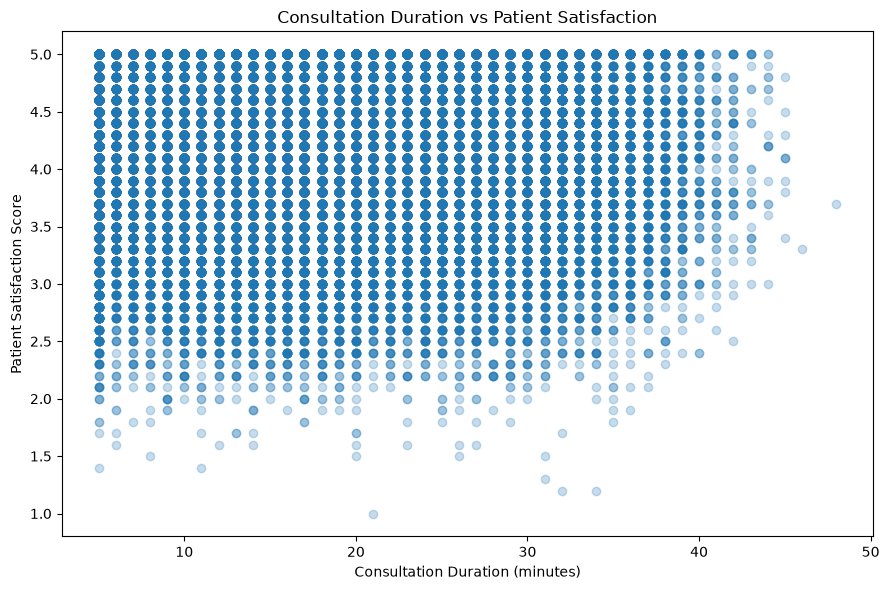

In [51]:
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("QUESTION 18 - CONSULTATION DURATION VS SATISFACTION")
print("=" * 70)

if (
    "consultation_duration_min" in completed.columns
    and "patient_satisfaction_score" in completed.columns
):
    duration_satisfaction = completed[
        ["consultation_duration_min",
         "patient_satisfaction_score"]
    ].dropna()

    duration_corr = duration_satisfaction.corr().iloc[0, 1]

    print(
        "\nCorrelation between consultation duration "
        "and satisfaction:"
    )
    print(round(duration_corr, 3))

    plt.figure(figsize=(9, 6))
    plt.scatter(
        duration_satisfaction["consultation_duration_min"],
        duration_satisfaction["patient_satisfaction_score"],
        alpha=0.25
    )
    plt.xlabel("Consultation Duration (minutes)")
    plt.ylabel("Patient Satisfaction Score")
    plt.title(
        "Consultation Duration vs Patient Satisfaction"
    )
    plt.tight_layout()
    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            "06_duration_vs_satisfaction.png"
        ),
        dpi=150
    )
    plt.show()


In [52]:
# ------------------------------------------------------------
# 24. DOCTOR EXPERIENCE VS CONSULTATION FEE



QUESTION 19 - DOCTOR EXPERIENCE VS CONSULTATION FEE

Merged columns:
['doctor_id', 'consultation_fee', 'experience_years', 'rating']

Average consultation fee by experience:
 experience_years  consultation_fee
                2           1361.26
                3           1170.69
                4           1434.05
                5           1331.00
                6           1683.07
                7           1398.96
                8           1506.90
                9           1139.43
               10           1744.84
               11           1326.27
               12           1625.21
               13           1355.77
               14           1715.85
               15           1765.58
               16           1585.24
               17           1367.02
               18           1489.94
               19           1439.39
               20           1985.52
               21           1593.14
               22           1869.34
               23           2084.

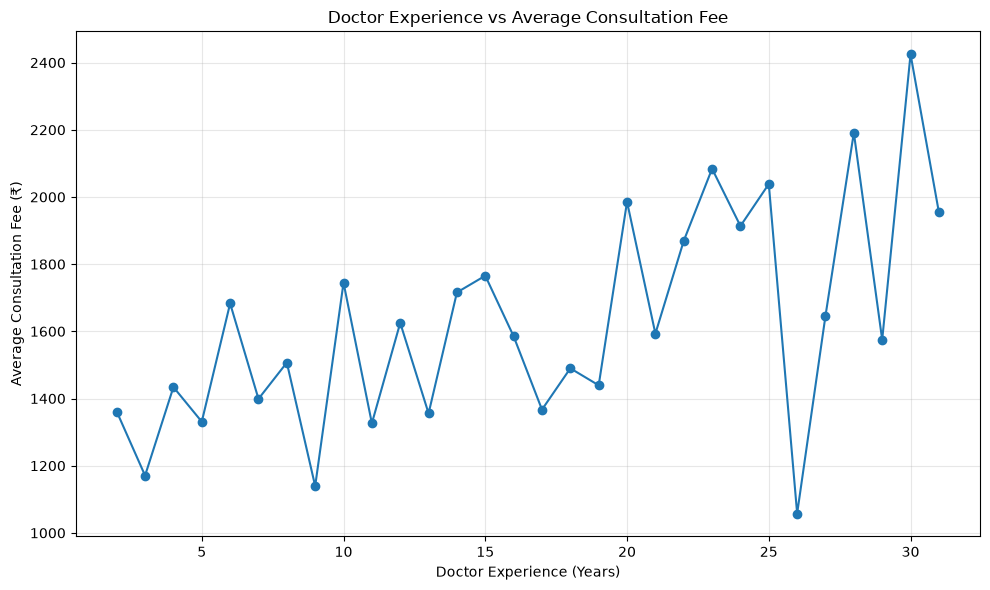

In [53]:
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("QUESTION 19 - DOCTOR EXPERIENCE VS CONSULTATION FEE")
print("=" * 70)

# SAFEST MERGE:
# Select only required columns from appointments and doctors.
# This prevents consultation_fee_x / consultation_fee_y problems.
completed_doctors = appointments[
    appointments["appointment_status"] == "Completed"
][["doctor_id", "consultation_fee"]].merge(
    doctors[
        ["doctor_id", "experience_years", "rating"]
    ],
    on="doctor_id",
    how="left"
)

print("\nMerged columns:")
print(completed_doctors.columns.tolist())

experience_fee = (
    completed_doctors
    .groupby(
        "experience_years",
        as_index=False
    )["consultation_fee"]
    .mean()
)

experience_fee["consultation_fee"] = (
    experience_fee["consultation_fee"].round(2)
)

print("\nAverage consultation fee by experience:")
print(experience_fee.to_string(index=False))

if len(experience_fee) > 0:
    highest_fee = experience_fee.loc[
        experience_fee["consultation_fee"].idxmax()
    ]

    lowest_fee = experience_fee.loc[
        experience_fee["consultation_fee"].idxmin()
    ]

    experience_corr = experience_fee[
        ["experience_years", "consultation_fee"]
    ].corr().iloc[0, 1]

    print("\nHighest average fee:")
    print(highest_fee)

    print("\nLowest average fee:")
    print(lowest_fee)

    print(
        "\nCorrelation between experience and average consultation fee:",
        round(experience_corr, 3)
    )

    plt.figure(figsize=(10, 6))
    plt.plot(
        experience_fee["experience_years"],
        experience_fee["consultation_fee"],
        marker="o"
    )
    plt.xlabel("Doctor Experience (Years)")
    plt.ylabel("Average Consultation Fee (₹)")
    plt.title(
        "Doctor Experience vs Average Consultation Fee"
    )
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            "07_experience_vs_consultation_fee.png"
        ),
        dpi=150
    )
    plt.show()


In [54]:
# ------------------------------------------------------------
# 25. FINAL TOP INSIGHTS


In [55]:
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("QUESTION 20 - FINAL INSIGHTS")
print("=" * 70)

# Overall no-show rate
overall_no_show = (
    (valid_appointments["appointment_status"] == "No-Show").sum()
    / len(valid_appointments)
    * 100
)

print(
    f"\n1. Overall no-show rate: {overall_no_show:.2f}%"
)

# Highest-risk specialty
if len(specialty_no_show) > 0:
    top_specialty = specialty_no_show.iloc[0]
    print(
        f"2. Highest no-show specialty: "
        f"{top_specialty['specialty']} "
        f"({top_specialty['no_show_rate_pct']:.2f}%)"
    )

# Highest-risk city
if len(city_no_show) > 0:
    top_city = city_no_show.iloc[0]
    print(
        f"3. Highest no-show city: "
        f"{top_city['city']} "
        f"({top_city['no_show_rate_pct']:.2f}%)"
    )

# Time of day
if "time_of_day" in appointments.columns:
    time_table = no_show_rate_table(
        appointments, "time_of_day"
    )
    if len(time_table) > 0:
        top_time = time_table.iloc[0]
        print(
            f"4. Highest-risk time of day: "
            f"{top_time['time_of_day']} "
            f"({top_time['no_show_rate_pct']:.2f}%)"
        )

# Appointment type
if "appointment_type" in appointments.columns:
    type_table = no_show_rate_table(
        appointments, "appointment_type"
    )
    if len(type_table) > 0:
        top_type = type_table.iloc[0]
        print(
            f"5. Highest-risk appointment type: "
            f"{top_type['appointment_type']} "
            f"({top_type['no_show_rate_pct']:.2f}%)"
        )

# Booking channel
if "booking_channel" in appointments.columns:
    channel_table = no_show_rate_table(
        appointments, "booking_channel"
    )
    if len(channel_table) > 0:
        top_channel = channel_table.iloc[0]
        print(
            f"6. Highest-risk booking channel: "
            f"{top_channel['booking_channel']} "
            f"({top_channel['no_show_rate_pct']:.2f}%)"
        )

# Revenue
if "consultation_fee" in no_shows.columns:
    risk = no_shows["consultation_fee"].sum()
    print(
        f"7. Potential listed consultation-fee revenue at risk: "
        f"₹{risk:,.2f}"
    )

# Completed revenue
if "revenue_realized" in completed.columns:
    total_completed_revenue = (
        completed["revenue_realized"].sum()
    )
    print(
        f"8. Completed realized revenue: "
        f"₹{total_completed_revenue:,.2f}"
    )

# Consultation duration / satisfaction
if (
    "consultation_duration_min" in completed.columns
    and "patient_satisfaction_score" in completed.columns
):
    print(
        f"9. Duration vs satisfaction correlation: "
        f"{duration_corr:.3f}"
    )

# Experience / fee
if len(experience_fee) > 0:
    print(
        f"10. Experience vs consultation fee correlation: "
        f"{experience_corr:.3f}"
    )



QUESTION 20 - FINAL INSIGHTS

1. Overall no-show rate: 15.94%
2. Highest no-show specialty: Psychiatry (24.52%)
3. Highest no-show city: Lucknow (17.19%)
4. Highest-risk time of day: Evening (18.37%)
5. Highest-risk appointment type: Home Visit (26.25%)
6. Highest-risk booking channel: Walk-In (20.88%)
7. Potential listed consultation-fee revenue at risk: ₹19,725,460.00
8. Completed realized revenue: ₹73,893,798.00
9. Duration vs satisfaction correlation: -0.004
10. Experience vs consultation fee correlation: 0.600


In [56]:
# ------------------------------------------------------------
# 26. BUSINESS RECOMMENDATIONS


In [57]:
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("QUESTION 21 - BUSINESS RECOMMENDATIONS")
print("=" * 70)

print("""
1. TARGET HIGH-RISK SPECIALTIES
   Focus reminder and confirmation campaigns on specialties
   with the highest no-show rates.

2. TARGET HIGH-RISK TIME SLOTS
   Evening and weekend appointments can receive stronger
   confirmation and reminder workflows when the data shows
   elevated no-show rates.

3. IMPROVE DIGITAL REMINDERS
   Use reminder-based interventions for appointments with
   higher no-show risk.

4. USE PATIENT HISTORY
   Patients with previous no-shows can be placed into a
   higher-risk segment for additional confirmation.

5. OPTIMISE APPOINTMENT CHANNELS
   Review high-risk booking channels and identify whether
   confirmation quality differs across channels.

6. PROTECT HIGH-VALUE APPOINTMENTS
   High-fee specialties and appointment types can receive
   priority confirmation because missed appointments have
   greater potential financial impact.

7. MONITOR WAITING TIME
   Identify specialties/doctors with high waiting times and
   investigate staffing or scheduling bottlenecks.

8. IMPROVE PATIENT EXPERIENCE
   Compare consultation duration and satisfaction to identify
   opportunities to improve service quality.

9. REVIEW DOCTOR CAPACITY
   Use utilisation metrics to balance overloaded and
   under-utilised doctors.

10. TRACK KPIs REGULARLY
    Build a dashboard for no-show rate, realised revenue,
    waiting time, utilisation, satisfaction and patient
    engagement.
""")



QUESTION 21 - BUSINESS RECOMMENDATIONS

1. TARGET HIGH-RISK SPECIALTIES
   Focus reminder and confirmation campaigns on specialties
   with the highest no-show rates.

2. TARGET HIGH-RISK TIME SLOTS
   Evening and weekend appointments can receive stronger
   confirmation and reminder workflows when the data shows
   elevated no-show rates.

3. IMPROVE DIGITAL REMINDERS
   Use reminder-based interventions for appointments with
   higher no-show risk.

4. USE PATIENT HISTORY
   Patients with previous no-shows can be placed into a
   higher-risk segment for additional confirmation.

5. OPTIMISE APPOINTMENT CHANNELS
   Review high-risk booking channels and identify whether
   confirmation quality differs across channels.

6. PROTECT HIGH-VALUE APPOINTMENTS
   High-fee specialties and appointment types can receive
   priority confirmation because missed appointments have
   greater potential financial impact.

7. MONITOR WAITING TIME
   Identify specialties/doctors with high waiting times 

In [58]:
# ------------------------------------------------------------
# 27. SAVE IMPORTANT OUTPUT TABLES


In [59]:
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SAVING OUTPUT TABLES")
print("=" * 70)

specialty_no_show.to_csv(
    os.path.join(OUTPUT_DIR, "specialty_no_show_rate.csv"),
    index=False
)

city_no_show.to_csv(
    os.path.join(OUTPUT_DIR, "city_no_show_rate.csv"),
    index=False
)

lead_bucket_analysis.to_csv(
    os.path.join(OUTPUT_DIR, "lead_time_analysis.csv"),
    index=False
)

if "appointment_type" in appointments.columns:
    type_no_show.to_csv(
        os.path.join(OUTPUT_DIR, "appointment_type_no_show.csv"),
        index=False
    )

if "booking_channel" in appointments.columns:
    channel_no_show.to_csv(
        os.path.join(OUTPUT_DIR, "booking_channel_no_show.csv"),
        index=False
    )

if "reminders_sent" in appointments.columns:
    reminder_analysis.to_csv(
        os.path.join(OUTPUT_DIR, "reminder_analysis.csv"),
        index=False
    )

if "revenue_realized" in completed.columns:
    specialty_revenue.to_csv(
        os.path.join(OUTPUT_DIR, "specialty_revenue.csv"),
        index=False
    )
    type_revenue.to_csv(
        os.path.join(OUTPUT_DIR, "appointment_type_revenue.csv"),
        index=False
    )
    city_revenue.to_csv(
        os.path.join(OUTPUT_DIR, "city_revenue.csv"),
        index=False
    )

experience_fee.to_csv(
    os.path.join(OUTPUT_DIR, "experience_vs_fee.csv"),
    index=False
)

print(
    f"\nAll available tables/charts have been saved in: "
    f"{OUTPUT_DIR}"
)

print("\n" + "=" * 70)
print("EDA PROJECT COMPLETE")
print("=" * 70)



SAVING OUTPUT TABLES

All available tables/charts have been saved in: apollo_eda_outputs

EDA PROJECT COMPLETE
